# Function 4 - Week 4: model review and next query

Start with the [observation review](observation_review.ipynb) for measured
progress and the latest return. This notebook compares models using
leave-one-out validation, then uses a Gaussian process and an acquisition
function to propose the next submission.

The saved Week 4 execution uses the independent `observations.csv`, including
the confirmed Week 3 return received on 14 October 2026. Review the validation,
noise assumptions and exploration-weight sensitivity before confirming a
decision; the calculated proposal is not a recorded Week 4 submission.

In [1]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import LeaveOneOut, cross_val_predict
import sys

shared_dir = Path.cwd().resolve().parents[1] / "Shared"
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from coverage_helpers import make_coverage_space
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS


In [2]:
# Data and output paths for this week's notebook.
# Start the kernel with this notebook's folder as its working directory.
week_dir = Path.cwd().resolve()
full_data_path = week_dir / "observations.csv"

if not (week_dir / "model_predictions.ipynb").is_file() or not full_data_path.is_file():
    raise FileNotFoundError(
        "Run this notebook with its own folder as the working directory; "
        "model_predictions.ipynb and observations.csv must be together."
    )

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

In [3]:
# Basic data load
print(f"Loading data from: {full_data_path}")
data = pd.read_csv(full_data_path, float_precision="round_trip")

Loading data from: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\stage-2-bbo\notebooks\Function_4\Week_04\observations.csv


In [4]:
# Column inspection
columns = data.columns
print("Columns: ", columns)

Columns:  Index(['observation_id', 'source_round', 'x1', 'x2', 'x3', 'x4', 'y'], dtype='str')


In [5]:
# Where we pray for good data, aka checking for nulls
print (data.isna().sum())

observation_id    0
source_round      0
x1                0
x2                0
x3                0
x4                0
y                 0
dtype: int64


In [6]:
# Splitting our data into inputs X and outputs y
output_column = "y"
# The course names inputs x1, x2, ...; preserve their CSV column order.
input_columns = [
    name for name in data.columns
    if name.startswith("x") and name[1:].isdigit()
]

#print("Input columns: ", input_columns)
#print("Output column: ", output_column)

X = data[input_columns]
y = data[output_column]

#print("The inputs are given by :")
#print(X.head())
#print("The outputs are given by :")
#print(y[:5])


In [7]:
# Set up leave-one-out validation for the model comparisons that follow.
cross_validation = LeaveOneOut()
number_of_folds = cross_validation.get_n_splits(X)

print(f"Validation folds: {number_of_folds}")
print(f"Training observations per fold: {len(X) - 1}")
print("Validation observations per fold: 1")

Validation folds: 33
Training observations per fold: 32
Validation observations per fold: 1


In [8]:
# Establish a mean-prediction benchmark using leave-one-out validation.
baseline_model = DummyRegressor(strategy="mean")

baseline_predictions = cross_val_predict(
    baseline_model,
    X,
    y,
    cv=cross_validation,
)

baseline_rmse = root_mean_squared_error(y, baseline_predictions)

print(f"Baseline RMSE: {baseline_rmse:.4f}")

Baseline RMSE: 8.4097


In [9]:
# Evaluate whether linear input effects improve on the mean baseline.
linear_model = LinearRegression()

linear_predictions = cross_val_predict(
    linear_model,
    X,
    y,
    cv=cross_validation,
)

linear_rmse = root_mean_squared_error(y, linear_predictions)
linear_improvement = 1 - linear_rmse / baseline_rmse

print(f"Mean baseline RMSE: {baseline_rmse:.4f}")
print(f"Linear regression RMSE: {linear_rmse:.4f}")
print(f"RMSE reduction against baseline: {linear_improvement:.1%}")

Mean baseline RMSE: 8.4097
Linear regression RMSE: 6.7117
RMSE reduction against baseline: 20.2%


In [10]:
# Evaluate linear regression with a penalty on large coefficients.
ridge_model = Ridge(alpha=1.0)

ridge_predictions = cross_val_predict(
    ridge_model,
    X,
    y,
    cv=cross_validation,
)

ridge_rmse = root_mean_squared_error(y, ridge_predictions)
ridge_improvement = 1 - ridge_rmse / baseline_rmse

print(f"Ridge regression RMSE: {ridge_rmse:.4f}")
print(f"RMSE reduction against baseline: {ridge_improvement:.1%}")

Ridge regression RMSE: 6.5972
RMSE reduction against baseline: 21.6%


In [11]:
# Evaluate a model that can capture curved input-output relationships.
kernel_ridge_model = KernelRidge(
    alpha=0.1,
    kernel="rbf",
    gamma=1.0,
)

kernel_ridge_predictions = cross_val_predict(
    kernel_ridge_model,
    X,
    y,
    cv=cross_validation,
)

kernel_ridge_rmse = root_mean_squared_error(y, kernel_ridge_predictions)
kernel_ridge_improvement = 1 - kernel_ridge_rmse / baseline_rmse

print(f"Kernel ridge regression RMSE: {kernel_ridge_rmse:.4f}")
print(f"RMSE reduction against baseline: {kernel_ridge_improvement:.1%}")

Kernel ridge regression RMSE: 4.5798
RMSE reduction against baseline: 45.5%


In [12]:
# Fit the selected model on every observation for predicting new locations.
selected_model = kernel_ridge_model
selected_model.fit(X, y)

print(f"Selected model: {type(selected_model).__name__}")
print(f"Observations used for the final fit: {len(X)}")
print(f"Input dimensions: {X.shape[1]}")

Selected model: KernelRidge
Observations used for the final fit: 33
Input dimensions: 4


In [13]:
# Predict outputs across a sampled candidate space and rank the locations.
candidate_inputs = pd.DataFrame(
    make_coverage_space(X.shape[1], power=14, seed=42),
    columns=input_columns,
)

candidate_results = candidate_inputs.copy()
candidate_results["predicted_y"] = selected_model.predict(candidate_inputs)
candidate_results = candidate_results.sort_values(
    "predicted_y",
    ascending=False,
).reset_index(drop=True)

best_candidate = candidate_results.iloc[0]

print(f"Candidate locations: {len(candidate_results):,}")
print(f"Best sampled prediction: {best_candidate['predicted_y']:.6f}")
print(f"Best observed output: {y.max():.6f}")

candidate_results.head(5)

Candidate locations: 16,400
Best sampled prediction: -4.669842
Best observed output: -0.129918


,x1,x2,x3,x4,predicted_y
0,0.446197,0.362993,0.241996,0.279191,-4.669842
1,0.370480,0.325727,0.282109,0.327866,-4.694267
2,0.347337,0.395981,0.322976,0.244407,-4.717012
3,0.405982,0.309877,0.258101,0.273710,-4.740409
4,0.434746,0.368250,0.217716,0.241206,-4.741717


In [14]:
# Check how the selected model represents the strongest observed outputs.
prediction_review = X.copy()
prediction_review["observed_y"] = y
prediction_review["fitted_y"] = selected_model.predict(X)

prediction_review["held_out_y"] = cross_val_predict(
    selected_model,
    X,
    y,
    cv=cross_validation,
)

prediction_review["fit_error"] = prediction_review["fitted_y"] - y
prediction_review["held_out_error"] = prediction_review["held_out_y"] - y

prediction_review.sort_values(
    "observed_y",
    ascending=False,
).head(5)

,x1,x2,x3,x4,observed_y,fitted_y,held_out_y,fit_error,held_out_error
31,0.445520,0.390792,0.374106,0.377372,-0.129918,-5.015796,-5.909109,-4.885878,-5.779191
32,0.459127,0.368781,0.430162,0.390645,-0.347965,-5.459361,-6.392992,-5.111396,-6.045027
30,0.377878,0.477308,0.239218,0.435290,-2.738157,-5.860090,-6.731576,-3.121932,-3.993418
27,0.577766,0.428772,0.425826,0.249007,-4.025542,-6.652924,-7.156126,-2.627381,-3.130584
24,0.326076,0.472367,0.453192,0.105887,-6.702089,-6.863821,-6.913989,-0.161732,-0.211899


In [15]:
# Evaluate a Gaussian process: predictions with uncertainty, as in Module 12.
# The RBF kernel describes smooth relationships between nearby inputs.
# Fit its amplitude and length scale using only each fold's training data.
# Noise SD is assumed to be 10% of the training output SD; this is not measured noise.
noise_fraction = 0.10

gaussian_process_model = GaussianProcessRegressor(
    kernel=ConstantKernel(1.0, (0.01, 100.0)) * RBF(
        length_scale=0.3,
        length_scale_bounds=(0.03, 2.0),
    ),
    alpha=noise_fraction ** 2,
    normalize_y=True,
    n_restarts_optimizer=3,
    random_state=42,
)

gaussian_process_predictions = cross_val_predict(
    gaussian_process_model,
    X,
    y,
    cv=cross_validation,
)
gaussian_process_rmse = root_mean_squared_error(y, gaussian_process_predictions)

model_comparison = pd.DataFrame({
    "Model": ["Mean baseline", "Linear regression", "Ridge", "Kernel ridge", "Gaussian process"],
    "LOO RMSE": [baseline_rmse, linear_rmse, ridge_rmse, kernel_ridge_rmse, gaussian_process_rmse],
})
model_comparison["RMSE reduction (%)"] = 100 * (1 - model_comparison["LOO RMSE"] / baseline_rmse)

print(f"Gaussian-process RMSE: {gaussian_process_rmse:.4f}")
model_comparison.sort_values("LOO RMSE").round(4)

Gaussian-process RMSE: 1.5382


,Model,LOO RMSE,RMSE reduction (%)
4,Gaussian process,1.5382,81.7095
3,Kernel ridge,4.5798,45.5410
2,Ridge,6.5972,21.5522
1,Linear regression,6.7117,20.1909
0,Mean baseline,8.4097,0.0000


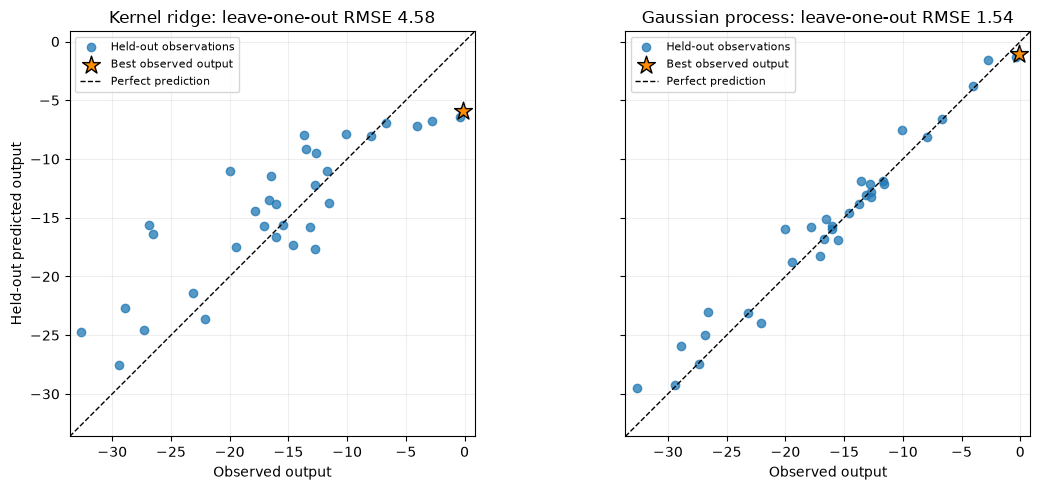

In [16]:
# Compare held-out predictions, with identical axes for both models.
# Every plotted prediction was made without that observation in the training set.
current_best_index = y.idxmax()
plot_min = float(min(y.min(), kernel_ridge_predictions.min(), gaussian_process_predictions.min())) - 1
plot_max = float(max(y.max(), kernel_ridge_predictions.max(), gaussian_process_predictions.max())) + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, name, predictions, error in [
    (axes[0], "Kernel ridge", kernel_ridge_predictions, kernel_ridge_rmse),
    (axes[1], "Gaussian process", gaussian_process_predictions, gaussian_process_rmse),
]:
    ax.scatter(y, predictions, alpha=0.75, label="Held-out observations")
    ax.scatter(
        y.loc[current_best_index],
        predictions[y.index.get_loc(current_best_index)],
        marker="*", s=180, color="darkorange", edgecolor="black",
        label="Best observed output",
    )
    ax.plot([plot_min, plot_max], [plot_min, plot_max], "k--", linewidth=1, label="Perfect prediction")
    ax.set(xlim=(plot_min, plot_max), ylim=(plot_min, plot_max),
           xlabel="Observed output", title=f"{name}: leave-one-out RMSE {error:.2f}")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Held-out predicted output")
fig.tight_layout()
fig.savefig(figures / "gaussian-process-validation.png", dpi=160, bbox_inches="tight")
plt.show()

In [17]:
# Use the Gaussian process for Bayesian candidate selection; fit all observations.
# The earlier kernel-ridge results remain a comparison with pure exploitation.
selected_model = gaussian_process_model
selected_model.fit(X, y)

print(f"Selected model: {type(selected_model).__name__}")
print(f"Observations used for the final fit: {len(X)}")
print(f"Fitted kernel: {selected_model.kernel_}")
print(f"Assumed noise SD: {noise_fraction * y.std(ddof=0):.4f} output units")

gaussian_process_review = X.copy()
gaussian_process_review["observed_y"] = y
gaussian_process_review["fitted_y"] = selected_model.predict(X)
gaussian_process_review["held_out_y"] = gaussian_process_predictions
gaussian_process_review["held_out_error"] = gaussian_process_predictions - y

gaussian_process_review.sort_values("observed_y", ascending=False).head(5)

Selected model: GaussianProcessRegressor
Observations used for the final fit: 33
Fitted kernel: 1.76**2 * RBF(length_scale=0.695)
Assumed noise SD: 0.8155 output units


,x1,x2,x3,x4,observed_y,fitted_y,held_out_y,held_out_error
31,0.445520,0.390792,0.374106,0.377372,-0.129918,-0.786450,-1.066559,-0.936640
32,0.459127,0.368781,0.430162,0.390645,-0.347965,-0.947720,-1.326805,-0.978839
30,0.377878,0.477308,0.239218,0.435290,-2.738157,-2.308749,-1.607720,1.130437
27,0.577766,0.428772,0.425826,0.249007,-4.025542,-3.886181,-3.769801,0.255742
24,0.326076,0.472367,0.453192,0.105887,-6.702089,-6.626409,-6.564173,0.137916


In [18]:
# Score the existing Sobol candidate space using Module 12's upper confidence bound.
# UCB = posterior mean + exploration weight * posterior standard deviation.
# Higher weights favour uncertain locations. The score is not a predicted output.
exploration_weight = 1.96

# Avoid proposing an already observed point at the portal's six-decimal precision.
observed_coordinates = set(map(tuple, X.round(6).to_numpy()))
is_new_candidate = [
    tuple(row) not in observed_coordinates
    for row in candidate_inputs.round(6).to_numpy()
]
bayesian_candidates = candidate_inputs.loc[is_new_candidate].copy().reset_index(drop=True)

candidate_mean, candidate_uncertainty = selected_model.predict(
    bayesian_candidates,
    return_std=True,
)
bayesian_candidates["posterior_mean"] = candidate_mean
bayesian_candidates["posterior_std"] = candidate_uncertainty
bayesian_candidates["ucb"] = candidate_mean + exploration_weight * candidate_uncertainty
bayesian_candidates = bayesian_candidates.sort_values("ucb", ascending=False).reset_index(drop=True)
recommended_candidate = bayesian_candidates.iloc[0]

print(f"Unobserved candidate locations: {len(bayesian_candidates):,}")
print(f"Best observed output: {y.max():.6f}")
print(f"Exploration weight: {exploration_weight}")
print("These are individual alternatives for the next query, not a planned batch.")
bayesian_candidates.head(5)

Unobserved candidate locations: 16,398
Best observed output: -0.129918
Exploration weight: 1.96
These are individual alternatives for the next query, not a planned batch.


,x1,x2,x3,x4,posterior_mean,posterior_std,ucb
0,0.354513,0.376712,0.378960,0.488593,-1.242048,0.644864,0.021886
1,0.343726,0.464050,0.456729,0.399526,-1.393412,0.719099,0.016022
2,0.390516,0.485457,0.418597,0.409830,-1.122003,0.568584,-0.007578
3,0.427088,0.388876,0.399036,0.350955,-0.916533,0.445900,-0.042570
4,0.395626,0.359244,0.381823,0.504599,-1.268944,0.620201,-0.053350


In [19]:
# Summarise one proposed query and check sensitivity to the exploration weight.
# The maximum is over our sampled candidates, not a proven global maximum.
next_query = recommended_candidate[input_columns].round(6)
next_query_inputs = pd.DataFrame([next_query.to_numpy()], columns=input_columns)
next_mean, next_std = selected_model.predict(next_query_inputs, return_std=True)

if not np.isfinite(next_query.to_numpy()).all() or not next_query.between(0, 0.999999).all():
    raise ValueError("The proposed query is outside the allowed input space.")
if tuple(next_query) in observed_coordinates:
    raise ValueError("The proposed query has already been observed.")

print("Proposed next query (input-column order):")
print(", ".join(f"{name}={value:.6f}" for name, value in next_query.items()))
print("Coordinates: " + ", ".join(f"{value:.6f}" for value in next_query))
print(f"Best observed output: {y.max():.6f}")
print(f"Predicted output at the proposed query: {next_mean[0]:.6f}")
print(f"Posterior standard deviation: {next_std[0]:.6f}")
print(f"Predicted improvement from the mean: {next_mean[0] - y.max():.6f}")
print(f"UCB acquisition score: {next_mean[0] + exploration_weight * next_std[0]:.6f}")
print("This is a model-based proposal, not a guaranteed improvement or a submission.")

# Check noise assumptions at this same proposed location; do not refit selected_model.
# This is a sensitivity check, not a search for the best noise setting.
noise_sensitivity = []
for assumed_noise_fraction in [0.03, noise_fraction, 0.30]:
    if assumed_noise_fraction == noise_fraction:
        sensitivity_model = selected_model
    else:
        sensitivity_model = clone(selected_model).set_params(alpha=assumed_noise_fraction ** 2)
        sensitivity_model.fit(X, y)
    sensitivity_mean, sensitivity_std = sensitivity_model.predict(next_query_inputs, return_std=True)
    noise_sensitivity.append({
        "Assumed noise fraction": assumed_noise_fraction,
        "Predicted output": sensitivity_mean[0],
        "Posterior SD": sensitivity_std[0],
        "Predicted mean improvement": sensitivity_mean[0] - y.max(),
    })

print("Predictions at the proposed query under different noise assumptions:")
print(pd.DataFrame(noise_sensitivity).round(6).to_string(index=False))
print("The noise fraction is an assumption; these checks do not establish the true noise level.")

exploration_sensitivity = []
for weight in [0.0, 1.0, 1.96, 3.0]:
    scores = bayesian_candidates["posterior_mean"] + weight * bayesian_candidates["posterior_std"]
    candidate = bayesian_candidates.loc[scores.idxmax()]
    exploration_sensitivity.append({
        "Exploration weight": weight,
        **candidate[input_columns].to_dict(),
        "Predicted output": candidate["posterior_mean"],
        "Posterior SD": candidate["posterior_std"],
    })

print("Selected locations under different exploration weights (0 means pure exploitation):")
pd.DataFrame(exploration_sensitivity).round(6)

Proposed next query (input-column order):
x1=0.354513, x2=0.376712, x3=0.378960, x4=0.488593
Coordinates: 0.354513, 0.376712, 0.378960, 0.488593
Best observed output: -0.129918
Predicted output at the proposed query: -1.242050
Posterior standard deviation: 0.644865
Predicted improvement from the mean: -1.112132
UCB acquisition score: 0.021885
This is a model-based proposal, not a guaranteed improvement or a submission.
Predictions at the proposed query under different noise assumptions:
 Assumed noise fraction  Predicted output  Posterior SD  Predicted mean improvement
                   0.03         -0.676434      0.370703                   -0.546515
                   0.10         -1.242050      0.644865                   -1.112132
                   0.30         -2.143640      1.417289                   -2.013722
The noise fraction is an assumption; these checks do not establish the true noise level.
Selected locations under different exploration weights (0 means pure exploitation):

,Exploration weight,x1,x2,x3,x4,Predicted output,Posterior SD
0,0.00,0.427088,0.388876,0.399036,0.350955,-0.916533,0.445900
1,1.00,0.427088,0.388876,0.399036,0.350955,-0.916533,0.445900
2,1.96,0.354513,0.376712,0.378960,0.488593,-1.242048,0.644864
3,3.00,0.306433,0.399692,0.471523,0.480635,-1.907935,0.927089


## Evidence for model-led queries

Use **GP RMSE / mean-baseline RMSE** as the main comparison: below 1 means better
held-out predictions than the baseline; 0.2 means one fifth of its error. The
existing model table reports the equivalent percentage reduction. This measures
predictive usefulness on the observed data, not the fraction of the input space explored.

Also check how many different locations the tested exploration weights select.
One location means this choice is stable across those weights for this candidate
sample and fitted model. Several locations mean the exploration trade-off still
changes the decision. Retain the noise-sensitivity check above.

The query budget provides context, not a confidence score. These checks do not
establish that exploration is complete or that the global optimum has been found;
GP uncertainty depends on its [kernel and noise assumptions](https://scikit-learn.org/stable/modules/gaussian_process.html).


In [20]:
# Reuse the validation and sensitivity results already calculated above: no new fits.
relative_gp_error = gaussian_process_rmse / baseline_rmse if baseline_rmse > 0 else None
weight_choices = pd.DataFrame(exploration_sensitivity)
distinct_choices = len(weight_choices[input_columns].round(6).drop_duplicates())

model_evidence = pd.DataFrame([
    {
        "Check": "GP / mean-baseline held-out RMSE",
        "Result": f"{relative_gp_error:.3f} (1.000 = baseline)" if relative_gp_error is not None else "Undefined: baseline error is zero",
    },
    {
        "Check": "RMSE in output units: GP / baseline",
        "Result": f"{gaussian_process_rmse:.4f} / {baseline_rmse:.4f}",
    },
    {
        "Check": "Distinct proposed locations across exploration weights",
        "Result": f"{distinct_choices} across {len(weight_choices)} tested weights (six-decimal inputs)",
    },
    {
        "Check": "Queries available from the start of this week",
        "Result": f"{remaining_queries(week_dir)} of the {TOTAL_QUERY_WEEKS}-query course allowance",
    },
])
model_evidence


,Check,Result
0,GP / mean-baseline held-out RMSE,0.183 (1.000 = baseline)
1,RMSE in output units: GP / baseline,1.5382 / 8.4097
2,Distinct proposed locations across exploration...,3 across 4 tested weights (six-decimal inputs)
3,Queries available from the start of this week,10 of the 13-query course allowance
